# 07 — Local and spectral Fresnel on the same optical system

Both paths receive the same two-component incident electric field, optical system, and detector. The sphere has **R/λ = 100**, index **1.5**, and illumination radius **35λ**. This is a specific beam benchmark, not a demonstration of general macroscopic accuracy.

The first transmitted Debye branch matches the retained forward path; full Mie includes additional scattering. We show fields before differences. Operator and convergence checks live in the test suite and `validation/propagation_branches.py`.


In [1]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import vecdiff_general as optics
from matplotlib.colors import PowerNorm
from matplotlib.ticker import FuncFormatter
from scipy.special import erfc
from vecdiff_general.visualization import plot_focal_polarization

%matplotlib inline
plt.rcParams.update({"image.cmap": "hot", "figure.dpi": 110, "font.size": 10})
root = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "validation/reference_data/focal_pipeline.npz").exists()
)

## Incident field and optical system

All lengths below are in vacuum wavelengths (λ = 1). No magnetic field or eikonal is supplied. The local branch estimates its phase gradient internally; the spectral branch uses angular-spectrum Fresnel.


In [2]:
air = optics.HomogeneousRegion("air", optics.Dielectric(1))
glass = optics.HomogeneousRegion("glass", optics.Dielectric(1.5))
axis = (np.arange(280) - 140) * 130 / 280
source_grid = optics.CartesianGrid(axis, axis, optics.Frame([0, 0, -105]))
rho = np.linalg.norm(source_grid.points[..., :2], axis=-1)
incident = optics.TransverseElectricField(
    source_grid,
    1,
    np.stack((0.5 * erfc((rho - 35) / 1.5), np.zeros_like(rho)), axis=-1),
)
system = optics.OpticalSystem(
    [
        optics.DielectricInterface(
            optics.SphericalCap(100, optics.Frame([0, 0, -100])), air, glass
        ),
        optics.DielectricInterface(
            optics.SphericalCap(-100, optics.Frame([0, 0, 100])), glass, air
        ),
    ]
)

## Propagate onto the same detector

The detector is fixed at z/λ = 146.9541667, covering [-12,12]λ in x and y. Each time includes source completion, operator preparation, both interfaces, and evaluation of the electric field. The requested target is separate from the optical system.


In [3]:
detector_axis = np.linspace(-12, 12, 121)
target = optics.Plane.z(146.95416666666665).sample(u=detector_axis, v=detector_axis)
propagators, fields, seconds = {}, {}, {}
for method in ("local", "spectral"):
    propagators[method] = optics.PropagationPipeline(system, transmission=method)
    start = perf_counter()
    fields[method] = propagators[method](incident, target)
    seconds[method] = perf_counter() - start

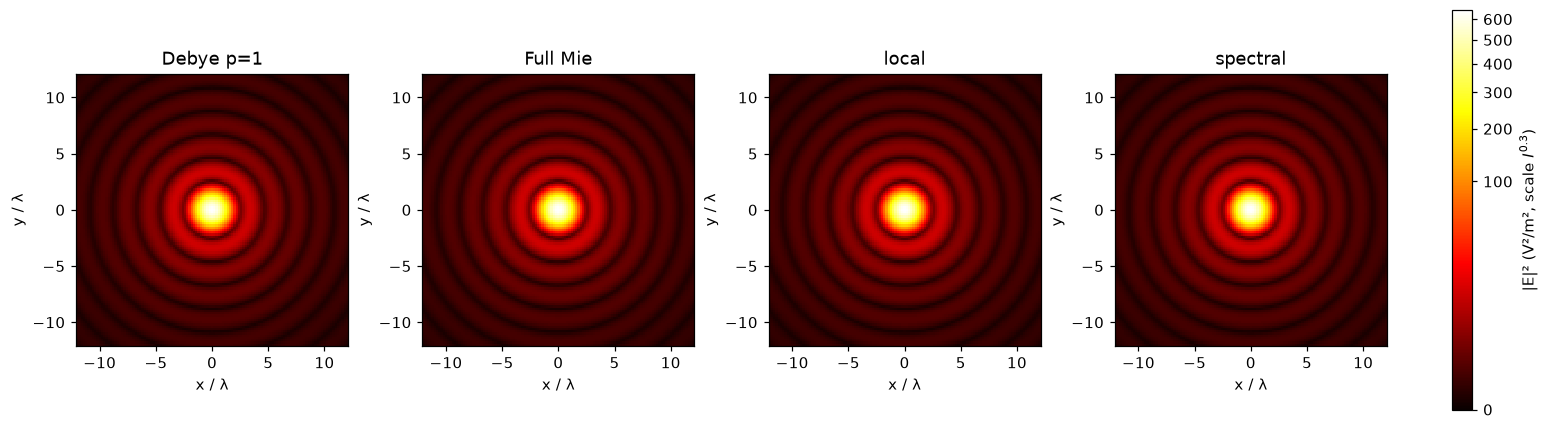

In [4]:
# Independent reference fields are loaded after the candidate calculations.
with np.load(root / "validation/reference_data/focal_pipeline.npz") as data:
    reference = {key: data[key].copy() for key in data.files}

maps = {
    "Debye p=1": reference["exact_plane_p1"],
    "Full Mie": reference["exact_plane_total"],
    **{method: field.values for method, field in fields.items()},
}
intensities = {name: np.sum(abs(values) ** 2, axis=-1) for name, values in maps.items()}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), layout="constrained")
maximum = max(values.max() for values in intensities.values())
for ax, (name, values) in zip(axes, intensities.items()):
    image = ax.pcolormesh(
        detector_axis,
        detector_axis,
        values,
        cmap="hot",
        # Compressed scale: the rings stay visible beside the focus.
        norm=PowerNorm(0.3, vmin=0, vmax=maximum),
        shading="auto",
    )
    ax.set(title=name, xlabel="x / λ", ylabel="y / λ", aspect="equal")
fig.colorbar(image, ax=axes, label="|E|² (V²/m², scale $I^{0.3}$)")
plt.show()

## Electric-field components

Separate $|E_x|^2$, $|E_y|^2$, and $|E_z|^2$ on the same focal detector. Each row uses one common **absolute intensity scale across all four calculations**; scales differ between rows so the weaker components remain visible. These are component intensities; the complex vector fields are retained for the differences below.

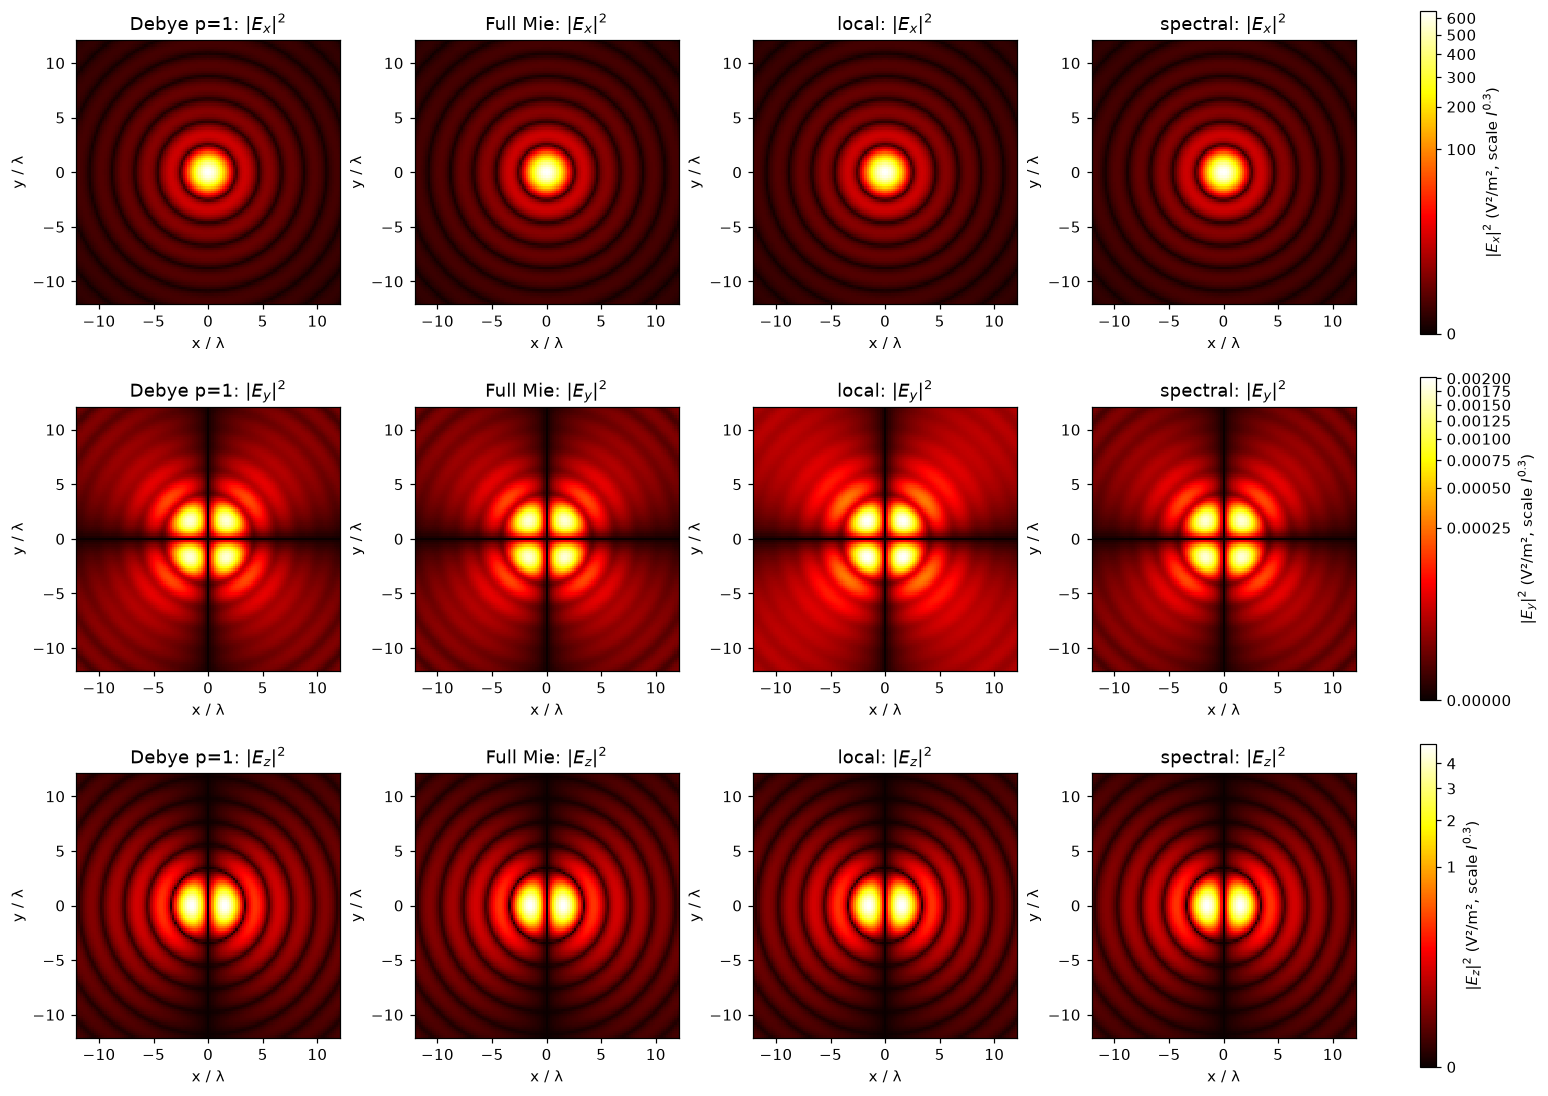

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(14, 10), layout="constrained")
for component, label in enumerate(("x", "y", "z")):
    maximum = max(np.max(abs(values[..., component]) ** 2) for values in maps.values())
    for ax, (name, values) in zip(axes[component], maps.items()):
        image = ax.pcolormesh(
            detector_axis,
            detector_axis,
            abs(values[..., component]) ** 2,
            cmap="hot",
            # Compressed scale: the rings stay visible beside the focus.
            norm=PowerNorm(0.3, vmin=0, vmax=maximum),
            shading="auto",
        )
        ax.set(
            title=rf"{name}: $|E_{label}|^2$",
            xlabel="x / λ",
            ylabel="y / λ",
            aspect="equal",
        )
    fig.colorbar(
        image, ax=axes[component], label=rf"$|E_{label}|^2$ (V²/m², scale $I^{{0.3}}$)"
    )
plt.show()

## Focal polarization

The crop $|x|, |y| \leq 8.6\lambda$ resolves the central spot and surrounding rings. All backgrounds show transverse intensity $(|E_x|^2+|E_y|^2)$ relative to the **same Debye p=1 on-axis value**, on a shared logarithmic `hot` scale from $10^{-5}$ to 1. Black glyphs show the transverse polarization ellipses; their display size varies logarithmically with intensity. This is the transverse polarization, not the full three-dimensional polarization including $E_z$.

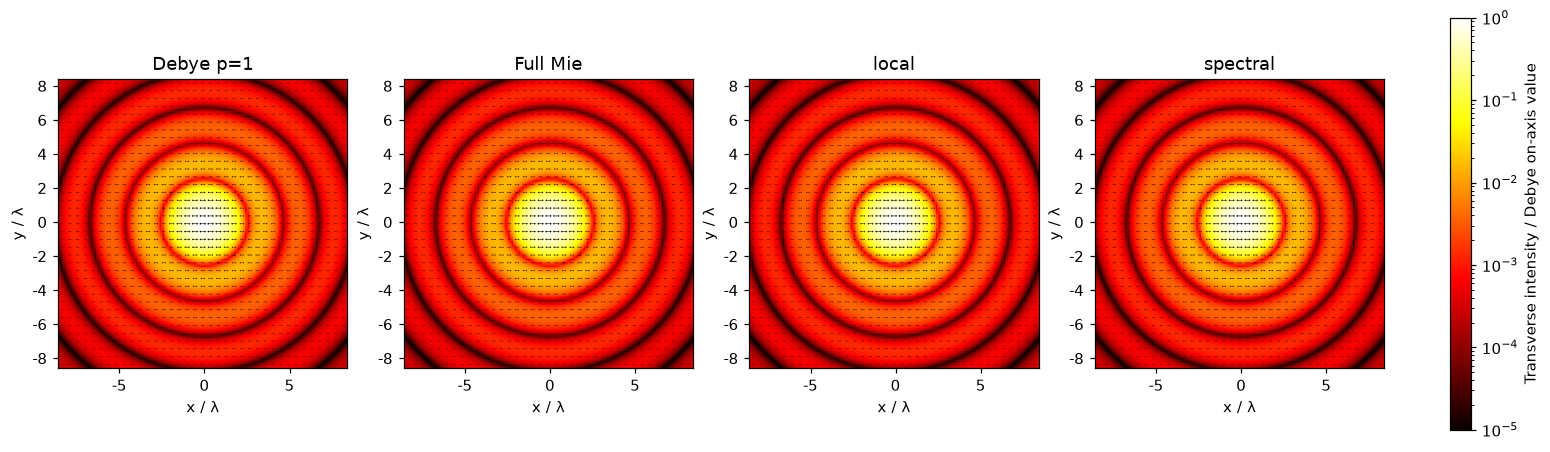

In [6]:
keep = np.flatnonzero(abs(detector_axis) <= 8.6)
polarization_grid = optics.Plane.z(target.frame.origin[2]).sample(
    u=detector_axis[keep], v=detector_axis[keep]
)
centre = len(detector_axis) // 2
reference_intensity = float(np.sum(abs(maps["Debye p=1"][centre, centre, :2]) ** 2))
fig, axes = plt.subplots(1, 4, figsize=(14, 4), layout="constrained")
for ax, (name, values) in zip(axes, maps.items()):
    plot_focal_polarization(
        optics.ElectricField(polarization_grid, 1, values[np.ix_(keep, keep)]),
        axis=ax,
        title=name,
        glyph="ellipse",
        reference_intensity=reference_intensity,
        floor=1e-5,
        colorbar=False,
    )
    # The shared helper displays coordinates in µm; this calculation uses λ = 1.
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value / 1e6:g}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value / 1e6:g}"))
    ax.set(xlabel="x / λ", ylabel="y / λ")
fig.colorbar(
    axes[0].images[0], ax=axes, label="Transverse intensity / Debye on-axis value"
)
plt.show()

## Complex-field differences and execution time

These are vector relative L2 differences over the displayed detector, with no gain, phase, or position fitting. They are not whole-space error bounds. Magnetic-field checks and the saved-spectral regression are performed by the external validation script.


In [7]:
from IPython.display import HTML, display


def relative(a, b):
    return np.linalg.norm(a - b) / np.linalg.norm(b)


rows = []
for method, field in fields.items():
    debye = 100 * relative(field.values, reference["exact_plane_p1"])
    mie = 100 * relative(field.values, reference["exact_plane_total"])
    rows.append(
        f"<tr><td>{method}</td><td>{debye:.5f}</td><td>{mie:.5f}</td><td>{seconds[method]:.3f}</td></tr>"
    )
display(
    HTML(
        "<table><tr><th>Treatment</th><th>E vs Debye (%)</th><th>E vs full Mie (%)</th><th>Complete E calculation (s)</th></tr>"
        + "".join(rows)
        + "</table>"
    )
)

Treatment,E vs Debye (%),E vs full Mie (%),Complete E calculation (s)
local,0.25915,0.47264,4.217
spectral,0.00619,0.41020,23.106


## Another target, reusing each prepared solution

An axial line is an explicit point grid. A transverse plane can also be requested directly as `propagator(incident, z=f)`; `x=b`, `y=a`, and placed curved surfaces use the same operator interface. Automatic sampling uses a documented source/path window; explicit windows are appropriate for focal crops.


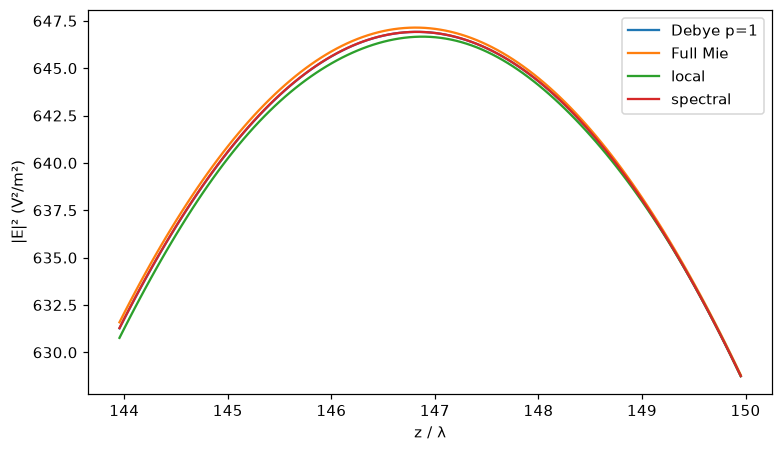

In [8]:
z_axis = reference["axis_z"]
axis_target = optics.PointGrid(
    np.column_stack((np.zeros_like(z_axis), np.zeros_like(z_axis), z_axis))
)
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
for name, values in [
    ("Debye p=1", reference["exact_axis_p1"]),
    ("Full Mie", reference["exact_axis_total"]),
]:
    ax.plot(z_axis, np.sum(abs(values) ** 2, axis=-1), label=name)
for method, propagator in propagators.items():
    axial = propagator(incident, axis_target)
    ax.plot(z_axis, axial.norm2(), label=method)
ax.set(xlabel="z / λ", ylabel="|E|² (V²/m²)")
ax.legend()
plt.show()